In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np, time
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tf = T.Compose([T.ToTensor(), T.Normalize((0.1307,), (0.3081,))])
mn_train = torchvision.datasets.MNIST('../data', train=True,  download=True, transform=tf)
mn_test  = torchvision.datasets.MNIST('../data', train=False, download=True, transform=tf)
mn_trainloader = torch.utils.data.DataLoader(mn_train, batch_size=64, shuffle=True,  num_workers=0)
mn_testloader  = torch.utils.data.DataLoader(mn_test,  batch_size=256, shuffle=False, num_workers=0)

Device: cuda


100%|██████████| 9.91M/9.91M [00:05<00:00, 1.76MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 105kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 899kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.74MB/s]


In [3]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, 5, padding=2)   # 28x28 -> 28x28 (padding mimics the 32x32 input)
        self.c2 = nn.Conv2d(6, 16, 5)             # 14x14 -> 10x10
        self.f1 = nn.Linear(16*5*5, 120)
        self.f2 = nn.Linear(120, 84)
        self.f3 = nn.Linear(84, 10)
    def forward(self, x):
        x = F.avg_pool2d(torch.tanh(self.c1(x)), 2)   # -> 14x14
        x = F.avg_pool2d(torch.tanh(self.c2(x)), 2)   # -> 5x5
        x = x.flatten(1)
        x = torch.tanh(self.f1(x))
        x = torch.tanh(self.f2(x))
        return self.f3(x)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                                 nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))  # 28->14->7->3
        self.drop = nn.Dropout(0.5)
        self.fc = nn.Linear(128*3*3, 10)
    def forward(self, x):
        return self.fc(self.drop(self.features(x).flatten(1)))

print(sum(p.numel() for p in LeNet5().parameters()), "params in LeNet-5")
print(sum(p.numel() for p in SmallCNN().parameters()), "params in SmallCNN")

61706 params in LeNet-5
104650 params in SmallCNN


In [4]:
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total, preds, truth = 0.0, 0, 0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += F.cross_entropy(out, y, reduction='sum').item()
            p = out.argmax(1)
            correct += (p == y).sum().item(); total += y.size(0)
            preds.append(p.cpu()); truth.append(y.cpu())
    return loss_sum/total, 100*correct/total, torch.cat(preds).numpy(), torch.cat(truth).numpy()

def train(model, epochs=10, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = dict(train_loss=[], train_acc=[], test_loss=[], test_acc=[])
    for ep in range(epochs):
        t0 = time.time()
        # train
        model.train()
        for x, y in mn_trainloader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            F.cross_entropy(model(x), y).backward()
            opt.step()
        # evaluate both sets in eval mode (so dropout/BN behave the same for both)
        trl, tra, _, _ = evaluate(model, mn_trainloader)
        tel, tea, _, _ = evaluate(model, mn_testloader)
        for k, v in zip(hist, (trl, tra, tel, tea)): hist[k].append(v)
        print(f"Epoch {ep+1:2d}/{epochs}  train loss {trl:.4f} acc {tra:.2f}%  |  "
              f"test loss {tel:.4f} acc {tea:.2f}%  ({time.time()-t0:.0f}s)")
    return hist

In [5]:
torch.manual_seed(0)
lenet = LeNet5();   hist_lenet = train(lenet)
torch.manual_seed(0)
small = SmallCNN(); hist_small = train(small)

Epoch  1/10  train loss 0.0866 acc 97.47%  |  test loss 0.0880 acc 97.38%  (32s)
Epoch  2/10  train loss 0.0505 acc 98.47%  |  test loss 0.0584 acc 98.25%  (29s)
Epoch  3/10  train loss 0.0399 acc 98.80%  |  test loss 0.0585 acc 98.28%  (29s)
Epoch  4/10  train loss 0.0313 acc 99.00%  |  test loss 0.0484 acc 98.47%  (29s)
Epoch  5/10  train loss 0.0236 acc 99.28%  |  test loss 0.0438 acc 98.62%  (29s)
Epoch  6/10  train loss 0.0191 acc 99.38%  |  test loss 0.0393 acc 98.63%  (30s)
Epoch  7/10  train loss 0.0194 acc 99.39%  |  test loss 0.0457 acc 98.59%  (30s)
Epoch  8/10  train loss 0.0170 acc 99.45%  |  test loss 0.0434 acc 98.75%  (30s)
Epoch  9/10  train loss 0.0105 acc 99.70%  |  test loss 0.0412 acc 98.62%  (30s)
Epoch 10/10  train loss 0.0130 acc 99.57%  |  test loss 0.0440 acc 98.72%  (29s)
Epoch  1/10  train loss 0.0449 acc 98.66%  |  test loss 0.0465 acc 98.60%  (31s)
Epoch  2/10  train loss 0.0256 acc 99.21%  |  test loss 0.0267 acc 99.04%  (32s)
Epoch  3/10  train loss 0.01

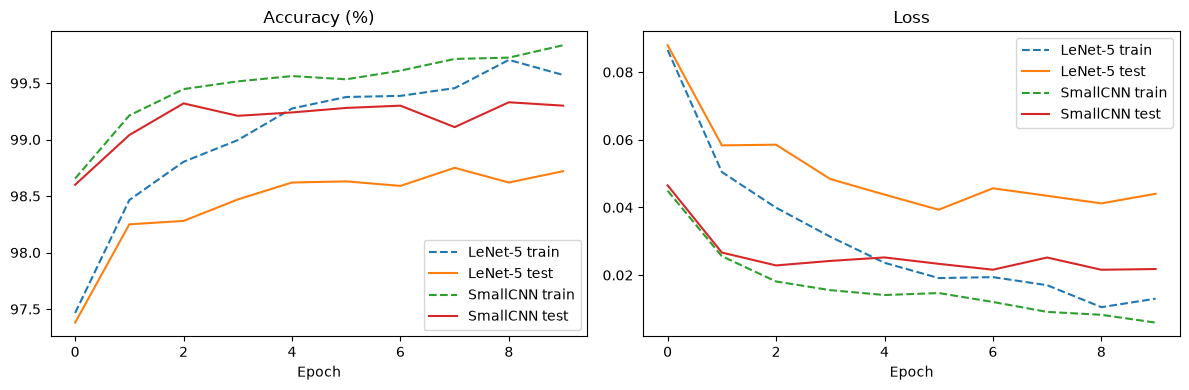

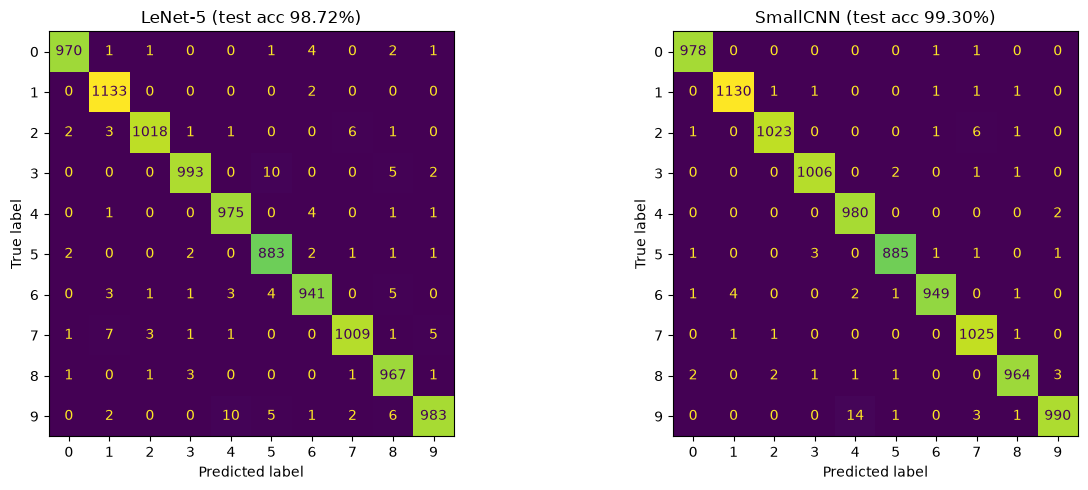

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [("LeNet-5", hist_lenet), ("SmallCNN", hist_small)]:
    ax[0].plot(h['train_acc'], '--', label=f"{name} train"); ax[0].plot(h['test_acc'], label=f"{name} test")
    ax[1].plot(h['train_loss'], '--', label=f"{name} train"); ax[1].plot(h['test_loss'], label=f"{name} test")
ax[0].set_title("Accuracy (%)"); ax[1].set_title("Loss")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (name, m) in zip(ax, [("LeNet-5", lenet), ("SmallCNN", small)]):
    _, acc, p, y = evaluate(m, mn_testloader)
    ConfusionMatrixDisplay(confusion_matrix(y, p)).plot(ax=a, colorbar=False)
    a.set_title(f"{name} (test acc {acc:.2f}%)")
plt.tight_layout(); plt.show()